### Mubhin Basnet Week 7

#Link to the google course:

https://drive.google.com/drive/folders/1JT_ktQhL7Dc1LLQ9QLzdTaFIgC9wdXcp?usp=sharing

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler


In [2]:
chocolates = {
    'Sugar': [30, 25, 35, 10, 15, 12, 5, 8, 6],
    'Cocoa': [40, 45, 35, 70, 65, 72, 85, 80, 88],
    'Price': [2, 2.5, 1.8, 3.5, 3.2, 3.8, 5, 4.5, 5.2]
}

df = pd.DataFrame(chocolates)
df


,Sugar,Cocoa,Price
0,30,40,2.0
1,25,45,2.5
2,35,35,1.8
3,10,70,3.5
4,15,65,3.2
5,12,72,3.8
6,5,85,5.0
7,8,80,4.5
8,6,88,5.2


In [3]:
def euclidean_similarity(x, y):
    return np.sqrt(np.sum((x - y) ** 2))


In [4]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df)


#K-Means Clustering

In [5]:
kmeans = KMeans(n_clusters=3, random_state=42)
clusters = kmeans.fit_predict(scaled_data)

df['Cluster'] = clusters
df


,Sugar,Cocoa,Price,Cluster
0,30,40,2.0,1
1,25,45,2.5,2
2,35,35,1.8,1
3,10,70,3.5,0
4,15,65,3.2,0
5,12,72,3.8,0
6,5,85,5.0,0
7,8,80,4.5,0
8,6,88,5.2,0


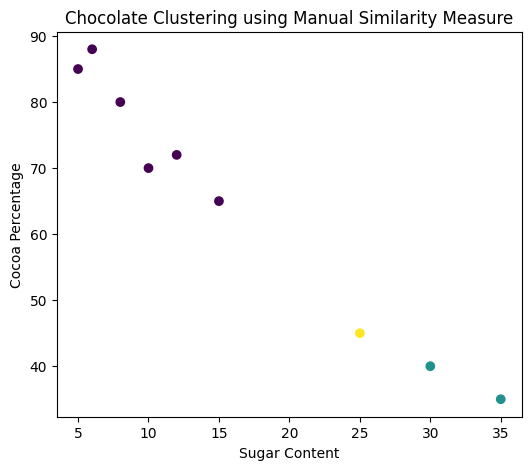

In [6]:
plt.figure(figsize=(6,5))
plt.scatter(df['Sugar'], df['Cocoa'], c=df['Cluster'], cmap='viridis')
plt.xlabel('Sugar Content')
plt.ylabel('Cocoa Percentage')
plt.title('Chocolate Clustering using Manual Similarity Measure')
plt.show()


#Clustering – Supervised Similarity with Chocolates


In [7]:
chocolates = {
    'Sugar': [30, 28, 35, 12, 15, 10, 6, 8, 5],
    'Cocoa': [40, 45, 38, 70, 65, 75, 85, 80, 90],
    'Price': [2, 2.3, 1.9, 3.5, 3.2, 3.8, 5, 4.6, 5.2],
    'Label': [0, 0, 0, 1, 1, 1, 2, 2, 2]
}

df = pd.DataFrame(chocolates)
df


,Sugar,Cocoa,Price,Label
0,30,40,2.0,0
1,28,45,2.3,0
2,35,38,1.9,0
3,12,70,3.5,1
4,15,65,3.2,1
5,10,75,3.8,1
6,6,85,5.0,2
7,8,80,4.6,2
8,5,90,5.2,2


In [8]:
X = df[['Sugar', 'Cocoa', 'Price']]
y = df['Label']

# Add supervised information
X_supervised = X.copy()
X_supervised['Label_Info'] = y * 0.5


In [9]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_supervised)


In [10]:
kmeans = KMeans(n_clusters=3, random_state=42)
df['Cluster'] = kmeans.fit_predict(X_scaled)

df


,Sugar,Cocoa,Price,Label,Cluster
0,30,40,2.0,0,1
1,28,45,2.3,0,1
2,35,38,1.9,0,1
3,12,70,3.5,1,0
4,15,65,3.2,1,0
5,10,75,3.8,1,0
6,6,85,5.0,2,2
7,8,80,4.6,2,2
8,5,90,5.2,2,2


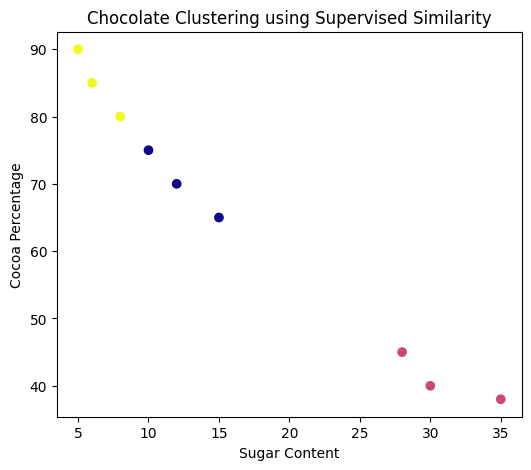

In [11]:
plt.figure(figsize=(6,5))
plt.scatter(df['Sugar'], df['Cocoa'], c=df['Cluster'], cmap='plasma')
plt.xlabel('Sugar Content')
plt.ylabel('Cocoa Percentage')
plt.title('Chocolate Clustering using Supervised Similarity')
plt.show()


#
